# INF201 Deliverable 1: Weather data from Ås

GitHub repository: https://github.com/fabianfeiler/inf201-h26-deliverable-1

In [1]:
from pathlib import Path

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import pandas as pd
import requests

CLIENT_ID_PATH = Path.home() / "frost_client_id.txt"


def read_client_id(path: Path = CLIENT_ID_PATH) -> str:
    """Read Frost client ID from a file outside the Git repository."""
    return path.read_text(encoding="utf-8").strip()


CLIENT_ID = read_client_id()

## Task 1: Temperature

The function for retrieving data is adapted from MET's Python example
(https://frost.met.no/python_example.html). We replaced `df.append()`,
which is removed in newer pandas, and read the client ID from a file
outside the repository.

In [2]:
# Adapted from MET's Frost Python example: https://frost.met.no/python_example.html
ENDPOINT = "https://frost.met.no/observations/v0.jsonld"


def fetch_frost(parameters: dict[str, str], client_id: str = CLIENT_ID) -> pd.DataFrame:
    """Fetch observations from Frost and return them as a DataFrame."""
    r = requests.get(ENDPOINT, parameters, auth=(client_id, ""), timeout=30)
    if r.status_code != 200:
        error = r.json()["error"]
        raise RuntimeError(f"Frost {r.status_code}: {error['message']} ({error['reason']})")
    rows = [
        {"referenceTime": item["referenceTime"], **obs}
        for item in r.json()["data"]
        for obs in item["observations"]
    ]
    df = pd.DataFrame(rows)
    df["referenceTime"] = pd.to_datetime(df["referenceTime"])
    return df[["referenceTime", "elementId", "value", "unit", "timeOffset"]]

The task suggests `referencetime = 2025-01-01/2025-12-31`, but Frost treats
the end date as exclusive, which returned only 364 days (31 December was
missing). We therefore use `2025-01-01/2026-01-01` to get the full year.

We also added `timeoffsets = default` and `levels = default`, as recommended
in MET's documentation. Without these, Frost can return several time series
for the same day (for example from different sensors), which would give
duplicate dates in the data.

In [3]:
TEMP_PARAMETERS = {
    "sources": "SN17850",
    "elements": "mean(air_temperature P1D)",
    "referencetime": "2025-01-01/2026-01-01",
    "timeoffsets": "default",
    "levels": "default",
}

temp_2025 = fetch_frost(TEMP_PARAMETERS)

print(f"Rows: {len(temp_2025)}")
print(f"Duplicate dates: {temp_2025['referenceTime'].duplicated().sum()}")
temp_2025.head()

Rows: 365
Duplicate dates: 0


,referenceTime,elementId,value,unit,timeOffset
0,2025-01-01 00:00:00+00:00,mean(air_temperature P1D),-5.2,degC,PT0H
1,2025-01-02 00:00:00+00:00,mean(air_temperature P1D),-11.5,degC,PT0H
2,2025-01-03 00:00:00+00:00,mean(air_temperature P1D),-8.9,degC,PT0H
3,2025-01-04 00:00:00+00:00,mean(air_temperature P1D),-15.5,degC,PT0H
4,2025-01-05 00:00:00+00:00,mean(air_temperature P1D),-12.5,degC,PT0H


In [4]:
all_days = pd.date_range("2025-01-01", "2025-12-31", tz="UTC")
missing = all_days.difference(temp_2025["referenceTime"])
print(missing)

DatetimeIndex([], dtype='datetime64[us, UTC]', freq='D')


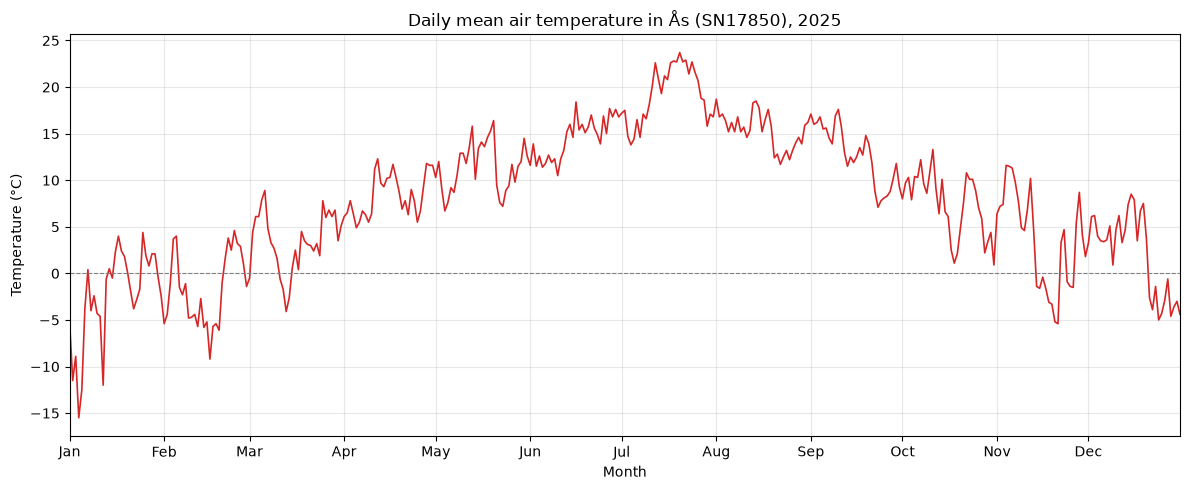

In [5]:
fig, ax = plt.subplots(figsize=(12, 5))

ax.plot(temp_2025["referenceTime"], temp_2025["value"], color="tab:red", linewidth=1.2)
ax.axhline(0, color="grey", linewidth=0.8, linestyle="--")

ax.set_title("Daily mean air temperature in Ås (SN17850), 2025")
ax.set_xlabel("Month")
ax.set_ylabel("Temperature (°C)")
ax.xaxis.set_major_locator(mdates.MonthLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b"))
ax.set_xlim(temp_2025["referenceTime"].min(), temp_2025["referenceTime"].max())
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [6]:
def summarize_temperature(df: pd.DataFrame, label: str) -> pd.DataFrame:
    """Return mean, median, min and max temperature as a one-column table."""
    stats = df["value"].agg(["mean", "median", "min", "max"]).round(1)
    stats.index = ["Mean", "Median", "Min", "Max"]
    return stats.to_frame(name=label)


summary_2025 = summarize_temperature(temp_2025, "2025 (°C)")
print(summary_2025)

        2025 (°C)
Mean          7.9
Median        8.3
Min         -15.5
Max          23.7


### Discussion of Task 1

The mean daily temperature in Ås in 2025 was **7.9 °C**, while the median was
**8.3 °C**. The median being slightly higher than the mean indicates that a few
very cold winter days pull the average down. The coldest day was 4 January
(**−15.5 °C**), and the warmest days occurred in the second half of July, with a
maximum of **23.7 °C**. This gives an annual range of almost 40 degrees.

The plot shows the expected seasonal pattern, with sub-zero temperatures in
January, February and December, and a clear peak in July. The day-to-day
variation is largest in winter, where temperatures shift by more than 10 degrees
within a few days.

Note that these are **daily means**. The actual lowest and highest temperatures
measured during 2025 were more extreme, since cold nights and warm afternoons
are averaged out. This becomes relevant in Task 4, where we use daily maximum
temperatures to identify heatwaves.

---

## Task 2: Precipitation

In [7]:
PRECIP_PARAMETERS = {
    "sources": "SN17850",
    "elements": "sum(precipitation_amount P1D)",
    "referencetime": "2025-01-01/2026-01-01",
    "timeoffsets": "default",
    "levels": "default",
}

precip_2025 = fetch_frost(PRECIP_PARAMETERS)

print(f"Rows: {len(precip_2025)}")
print(f"Duplicate dates: {precip_2025['referenceTime'].duplicated().sum()}")
precip_2025.head()

Rows: 365
Duplicate dates: 0


,referenceTime,elementId,value,unit,timeOffset
0,2025-01-01 00:00:00+00:00,sum(precipitation_amount P1D),6.6,mm,PT6H
1,2025-01-02 00:00:00+00:00,sum(precipitation_amount P1D),1.9,mm,PT6H
2,2025-01-03 00:00:00+00:00,sum(precipitation_amount P1D),0.1,mm,PT6H
3,2025-01-04 00:00:00+00:00,sum(precipitation_amount P1D),0.0,mm,PT6H
4,2025-01-05 00:00:00+00:00,sum(precipitation_amount P1D),0.0,mm,PT6H


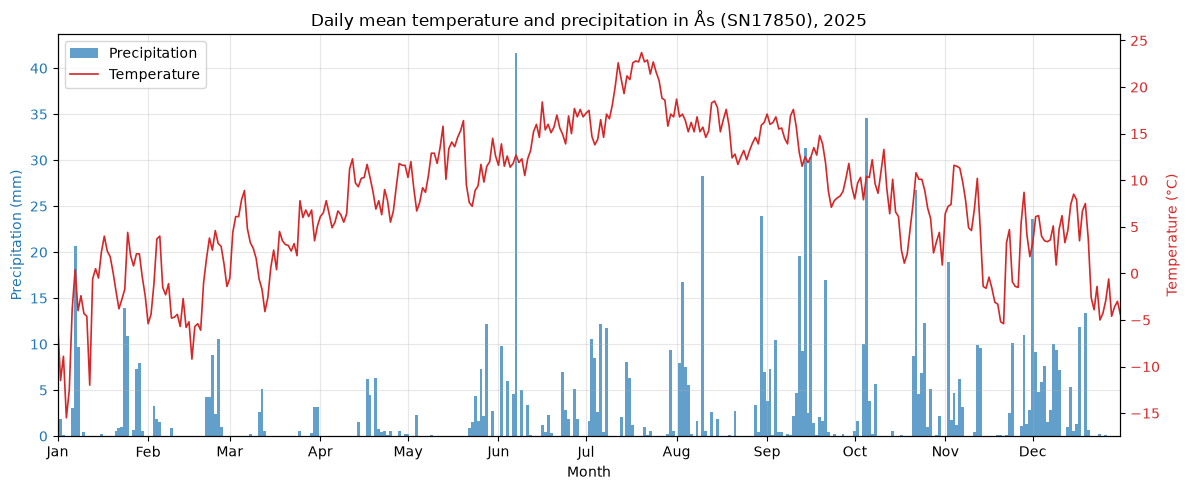

In [8]:
fig, ax1 = plt.subplots(figsize=(12, 5))

ax1.bar(
    precip_2025["referenceTime"],
    precip_2025["value"],
    color="tab:blue",
    width=1.0,
    alpha=0.7,
    label="Precipitation",
)
ax1.set_ylabel("Precipitation (mm)", color="tab:blue")
ax1.tick_params(axis="y", labelcolor="tab:blue")

ax2 = ax1.twinx()
ax2.plot(
    temp_2025["referenceTime"],
    temp_2025["value"],
    color="tab:red",
    linewidth=1.2,
    label="Temperature",
)
ax2.set_ylabel("Temperature (°C)", color="tab:red")
ax2.tick_params(axis="y", labelcolor="tab:red")

ax1.set_title("Daily mean temperature and precipitation in Ås (SN17850), 2025")
ax1.set_xlabel("Month")
ax1.xaxis.set_major_locator(mdates.MonthLocator())
ax1.xaxis.set_major_formatter(mdates.DateFormatter("%b"))
ax1.set_xlim(temp_2025["referenceTime"].min(), temp_2025["referenceTime"].max())
ax1.grid(alpha=0.3)

h1, l1 = ax1.get_legend_handles_labels()
h2, l2 = ax2.get_legend_handles_labels()
ax1.legend(h1 + h2, l1 + l2, loc="upper left")

plt.tight_layout()
plt.show()

### Discussion of Task 2

The plot shows daily mean temperature as a red line (right axis) and daily precipitation as blue bars (left axis). We used two y-axes because the two measurements have different units and value ranges. A line suits temperature since it changes gradually from day to day, while bars suit precipitation since it is an amount accumulated over each day.

Precipitation is spread across the whole year, with many dry days and a few days with heavy rainfall. The wettest day was in June, with about 42 mm. There is no clear day-to-day relationship between temperature and precipitation in the plot, but the temperature follows the same seasonal pattern as in Task 1.


---

## Task 3: Historical temperature data


In [9]:
OLD_TEMP_PARAMETERS = {
    "sources": "SN17850",
    "elements": "mean(air_temperature P1D)",
    "referencetime": "1925-01-01/1926-01-01",
    "timeoffsets": "default",
    "levels": "default",
}

temp_1925 = fetch_frost(OLD_TEMP_PARAMETERS)

print(f"Rows: {len(temp_1925)}")
print(f"Duplicate dates: {temp_1925['referenceTime'].duplicated().sum()}")
temp_1925.head()

Rows: 365
Duplicate dates: 0


,referenceTime,elementId,value,unit,timeOffset
0,1925-01-01 00:00:00+00:00,mean(air_temperature P1D),1.3,degC,PT0H
1,1925-01-02 00:00:00+00:00,mean(air_temperature P1D),4.1,degC,PT0H
2,1925-01-03 00:00:00+00:00,mean(air_temperature P1D),2.1,degC,PT0H
3,1925-01-04 00:00:00+00:00,mean(air_temperature P1D),0.1,degC,PT0H
4,1925-01-05 00:00:00+00:00,mean(air_temperature P1D),-2.2,degC,PT0H


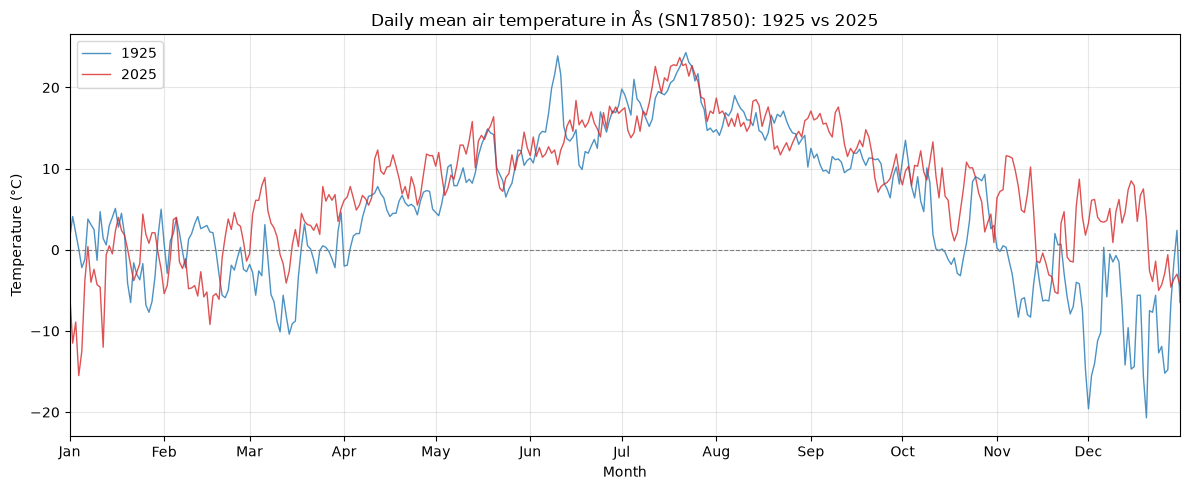

In [10]:
temp_1925_shifted = temp_1925["referenceTime"] + pd.DateOffset(years=100)

fig, ax = plt.subplots(figsize=(12, 5))

ax.plot(temp_1925_shifted, temp_1925["value"], color="tab:blue", linewidth=1.0, alpha=0.8, label="1925")
ax.plot(temp_2025["referenceTime"], temp_2025["value"], color="tab:red", linewidth=1.0, alpha=0.8, label="2025")
ax.axhline(0, color="grey", linewidth=0.8, linestyle="--")

ax.set_title("Daily mean air temperature in Ås (SN17850): 1925 vs 2025")
ax.set_xlabel("Month")
ax.set_ylabel("Temperature (°C)")
ax.xaxis.set_major_locator(mdates.MonthLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b"))
ax.set_xlim(temp_2025["referenceTime"].min(), temp_2025["referenceTime"].max())
ax.grid(alpha=0.3)
ax.legend(loc="upper left")

plt.tight_layout()
plt.show()

In [11]:
summary_compare = pd.concat([summarize_temperature(temp_1925, "1925 (°C)"), summary_2025], axis=1)
print(summary_compare)

        1925 (°C)  2025 (°C)
Mean          5.3        7.9
Median        5.3        8.3
Min         -20.7      -15.5
Max          24.3       23.7


### Discussion of Task 3

We compared the daily mean temperature in Ås in 2025 with 1925. The mean temperature was 5.3 °C in 1925 and 7.9 °C in 2025, a difference of about 2.6 °C, so 2025 was warmer. The median shows the same: 5.3 °C in 1925 against 8.3 °C in 2025. The coldest day was colder in 1925 (-20.7 °C) than in 2025 (-15.5 °C), while the warmest day was similar in both years (24.3 °C in 1925 and 23.7 °C in 2025).

Both years follow the same seasonal pattern, but the day to day variation is large in both, so single days or short periods cannot be compared directly. Two single years also cannot say anything certain about long-term climate change, since weather varies a lot from year to year. We checked the number of rows for 1925 and all 365 days were available.

To compare the two years in the same plot, the 1925 dates are shifted forward by 100 years so both series share the same x-axis. Measurements from 1925 may also be affected by different instruments and observation routines, which adds uncertainty to the comparison.